# 05 — MLP v1: shared vocabulary

First model. 2-layer MLP (`37 → 80 → 107`), all 7 event fields sharing one
107-wide output vocabulary, categorical fields fed as raw scalar codes,
`BCEWithLogits` loss. Split now comes from `03_splits` — this notebook just
reads `train_set.csv` / `val_set.csv` / `test_set.csv`.

Evaluation write-up: `evaluations/mlp_v1.md` (kept in `scratch/`).
Continues in `06_mlp_v1_evaluation.ipynb` (human baseline + analysis).

In [1]:
import warnings
from statsbombpy.api_client import NoAuthWarning
from socceraction.data.statsbomb import StatsBombLoader
import pandas as pd
from statsbombpy import sb
import numpy as np
import json
import socceraction.spadl as spadl

warnings.filterwarnings("ignore", category=NoAuthWarning)
warnings.filterwarnings("ignore", message="credentials were not supplied")

pd.set_option("display.max_columns", None)  # Show all columns

In [ ]:
# split now lives in 03_splits — just read its output (keeping the frame
# names the eval/sampling helpers below already use)
df_shuffled1 = pd.read_csv("data/train_set.csv")
df_shuffled2 = pd.read_csv("data/val_set.csv")
df_shuffled3 = pd.read_csv("data/test_set.csv")
ml_df = df_shuffled1

In [5]:
import json

with open("data/event_masks.json") as f:
    masks = json.load(f)

with open("data/category_lookup.json") as f:
    lookup = json.load(f)

In [6]:
lookup = {
    col: {int(k): v for k, v in mapping.items()}
    for col, mapping in lookup.items()
}

In [7]:
masks = {
    col: [106 if v == -2 else v for v in vals]
    for col, vals in masks.items()
}

In [10]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline
import random

random.seed(42)
g = torch.Generator().manual_seed(42)  # shared generator for every torch random draw below

In [16]:
def build_dataset(df):
    X = df[
        [
            "is_home",
            "event",
            "start_x",
            "start_y",
            "time_elapsed",
            "duration",
            "result",
            "period_id",
            "minute",
            "second",
            "home_goal_count",
            "away_goal_count",
            "home_red_count",
            "away_red_count",
            "home_yellow_count",
            "away_yellow_count",
            "is_home-1",
            "event-1",
            "start_x-1",
            "start_y-1",
            "time_elapsed-1",
            "duration-1",
            "result-1",
            "is_home-2",
            "event-2",
            "start_x-2",
            "start_y-2",
            "time_elapsed-2",
            "duration-2",
            "result-2",
            "is_home-3",
            "event-3",
            "start_x-3",
            "start_y-3",
            "time_elapsed-3",
            "duration-3",
            "result-3",
            "target",
        ]
    ]
    X = X.drop(['target'], axis=1)
    X = torch.tensor(X.values).float()

    Y = df['target']
    Y = torch.tensor(Y.values).float()
    Y = F.one_hot(Y.long(), num_classes=107).float()

    return X, Y

In [ ]:
Xtr, Ytr = build_dataset(df_shuffled1)
Xval, Yval = build_dataset(df_shuffled2)
Xte, Yte = build_dataset(df_shuffled3)

In [18]:
Xtr.shape, Xval.shape, Xte.shape

(torch.Size([4150517, 37]), torch.Size([523817, 37]), torch.Size([517216, 37]))

## Baseline: zeroed inputs

In [19]:
n_hidden = 80
vocab_size = len(Ytr[0])

g_baseline = torch.Generator().manual_seed(42)

W1_baseline = torch.randn((Xtr.shape[1], n_hidden), generator=g_baseline) * 0.001
b1_baseline = torch.randn(n_hidden, generator=g_baseline) * 0
W2_baseline = torch.randn((n_hidden, vocab_size), generator=g_baseline) * 0.001
b2_baseline = torch.randn(vocab_size, generator=g_baseline) * 0

baseline_parameters = [W1_baseline, b1_baseline, W2_baseline, b2_baseline]

for p in baseline_parameters:
    p.requires_grad = True

baseline_lossi = []

In [20]:
baseline_steps = 100000
baseline_batch_size = 512
baseline_lr = 0.1


for i in range(baseline_steps):
    ix = torch.randint(0, Xtr.shape[0], (baseline_batch_size,), generator=g_baseline)
    Xb, Yb = torch.zeros_like(Xtr[ix]), Ytr[ix]
    
    #forward pass
    
    hpreact = Xb @ W1_baseline + b1_baseline
    h = torch.relu(hpreact)
    
    logits = h @ W2_baseline + b2_baseline
    
    loss = F.binary_cross_entropy_with_logits(logits, Yb)
    
    baseline_lossi.append(loss.item())
    
    # backward pass
    
    for p in baseline_parameters:
        p.grad = None
        
    loss.backward()
    
    for p in baseline_parameters:
        p.data += -baseline_lr * p.grad

    if i % 10000 == 0:
        print(i, loss.item())
    
#baseline_lossi

0 0.6931473016738892
10000 0.13481079041957855
20000 0.08160948008298874
30000 0.06387608498334885
40000 0.055576205253601074
50000 0.049600664526224136
60000 0.04690098017454147
70000 0.04590856656432152
80000 0.044172968715429306
90000 0.04315793514251709


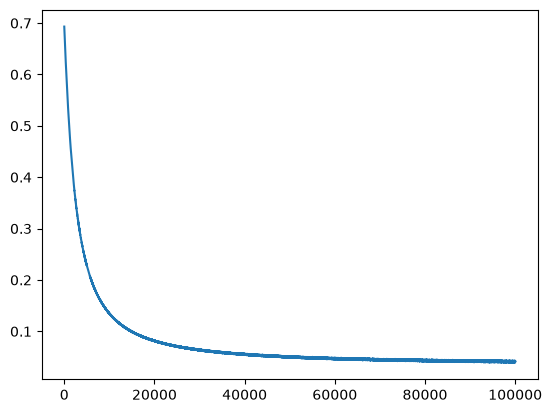

In [21]:
plt.plot(range(len(baseline_lossi)), baseline_lossi)

In [22]:
np.mean(baseline_lossi[:20]), np.mean(baseline_lossi[-20:])

(0.6910046935081482, 0.04119723606854677)

In [23]:
with torch.no_grad():
    hpreact = torch.zeros_like(Xval) @ W1_baseline + b1_baseline
    h = torch.relu(hpreact)
    logits = h @ W2_baseline + b2_baseline
    baseline_val_loss = F.binary_cross_entropy_with_logits(logits, Yval)

baseline_val_loss.item()

0.04110134765505791

## Real model

In [24]:
event_cols = ['is_home', 'event', 'start_x', 'start_y', 'time_elapsed', 'duration', 'result']

with torch.no_grad():
    start = torch.zeros((1, Xtr.shape[1]))

    for i, field in enumerate(event_cols):
        mask = masks[field]

        hpreact = start @ W1_baseline + b1_baseline
        h = torch.relu(hpreact)

        logits = h @ W2_baseline + b2_baseline
        restricted_logits = logits[:, mask]

        ix = restricted_logits.argmax(dim=1)
        mask = torch.tensor(mask)
        value = mask[ix].item()
        value = -2 if value == 106 else value

        start[0, i] = value

        if field in lookup:
            print(field, value, lookup[field][value])
        else:
            print(field, value)

is_home 1 home
event 1 pass
start_x 1
start_y 1
time_elapsed 1
duration 1
result 1 fail


In [25]:
n_hidden = 80
vocab_size = len(Ytr[0])

W1 = torch.randn((Xtr.shape[1], n_hidden), generator=g) * 0.001
b1 = torch.randn(n_hidden, generator=g) * 0
W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.001
b2 = torch.randn(vocab_size, generator=g) * 0

parameters = [W1, b1, W2, b2]

for p in parameters:
    p.requires_grad = True

lossi = []

In [ ]:
max_steps = 1000000
batch_size = 512


def get_lr(step):
    if step < 500000:
        return 0.1
    elif step < 850000:
        return 0.01
    else:
        return 0.001


for i in range(max_steps):
    lr = get_lr(i)
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]
    
    #forward pass
    
    hpreact = Xb @ W1 + b1
    h = torch.relu(hpreact)
    
    logits = h @ W2 + b2
    
    loss = F.binary_cross_entropy_with_logits(logits, Ytr[ix])
    
    # backward pass
    
    for p in parameters:
        p.grad = None
        
    loss.backward()
    
    for p in parameters:
        p.data += -lr * p.grad

    if i % 50000 == 0:
        with torch.no_grad():
            val_hpreact = Xval @ W1 + b1
            val_h = torch.relu(val_hpreact)
            val_logits = val_h @ W2 + b2
            val_loss = F.binary_cross_entropy_with_logits(val_logits, Yval)

        lossi.append(val_loss.item())
        print(i, lr, val_loss.item())

with torch.no_grad():
    val_hpreact = Xval @ W1 + b1
    val_h = torch.relu(val_hpreact)
    val_logits = val_h @ W2 + b2
    val_loss = F.binary_cross_entropy_with_logits(val_logits, Yval)

lossi.append(val_loss.item())
print(max_steps, lr, val_loss.item())

#lossi

0 0.1 0.692710280418396
50000 0.1 0.030837412923574448
100000 0.1 0.028631627559661865
150000 0.1 0.02674146741628647
200000 0.1 0.02604641206562519
250000 0.1 0.025685925036668777
300000 0.1 0.025309227406978607
350000 0.1 0.025366537272930145
400000 0.1 0.024717217311263084
450000 0.1 0.02441534958779812
500000 0.01 0.024206586182117462
550000 0.01 0.024076418951153755
600000 0.01 0.024049583822488785
650000 0.01 0.02402978576719761
700000 0.01 0.023999804630875587
750000 0.01 0.023974962532520294
800000 0.01 0.023945946246385574
850000 0.001 0.02392878569662571
900000 0.001 0.02391505241394043
950000 0.001 0.023913560435175896
1000000 0.001 0.023909876123070717


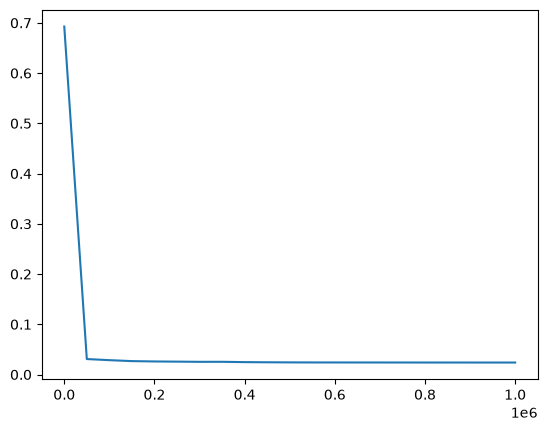

In [27]:
plt.plot(range(0, len(lossi) * 50000, 50000), lossi)

In [28]:
lossi[0], lossi[-1]

(0.692710280418396, 0.023909876123070717)

## Evaluation

In [29]:
unif = torch.ones((106,)) 
unif = unif / sum(unif)

tgt = F.one_hot(torch.tensor(0), 106)

F.binary_cross_entropy_with_logits(unif, tgt.float())

tensor(0.6978)

In [30]:
@torch.no_grad()  # this decorator disables gradient tracking
def split_loss(split):
    x, y = {
        "train": (Xtr, Ytr),
        "val": (Xval, Yval),
        "test": (Xte, Yte),
    }[
        split
    ]  # (N, block_size, n_embd)

    hpreact = x @ W1 + b1
    h = torch.relu(hpreact)

    logits = h @ W2 + b2  # (N, vocab_size)
    loss = F.binary_cross_entropy_with_logits(logits, y)
    print(split, loss.item())


def split_accuracy(split):
    x, y = {
        "train": (Xtr, Ytr),
        "val": (Xval, Yval),
        "test": (Xte, Yte),
    }[
        split
    ]  # (N, block_size, n_embd)

    hpreact = x @ W1 + b1
    h = torch.relu(hpreact)

    logits = h @ W2 + b2 
    ix = logits.argmax(dim=1)
    was_accurate = y[torch.arange(y.shape[0]), ix]

    accuracy = was_accurate.sum() /len(was_accurate)
    print(split, accuracy.item())

In [31]:
event_cols = ['is_home', 'event', 'start_x', 'start_y', 'time_elapsed', 'duration', 'result']
acc_fields = ['is_home', 'event', 'result']


@torch.no_grad()
def split_accuracy_by_field(split):
    x, y, step = {
        "train": (Xtr, Ytr, df_shuffled1['step'].values),
        "val": (Xval, Yval, df_shuffled2['step'].values),
        "test": (Xte, Yte, df_shuffled3['step'].values),
    }[split]

    step = torch.tensor(step)

    hpreact = x @ W1 + b1
    h = torch.relu(hpreact)

    logits = h @ W2 + b2
    ix = logits.argmax(dim=1)
    true = y.argmax(dim=1)

    for i, field in enumerate(event_cols):
        mask = step == i
        pred_i, true_i = ix[mask], true[mask]

        if field in acc_fields:
            was_accurate = pred_i == true_i
            accuracy = was_accurate.sum() / len(was_accurate)
            print(split, field, 'accuracy', accuracy.item())
        else:
            pred_val = torch.where(pred_i == 106, torch.tensor(-2), pred_i)
            true_val = torch.where(true_i == 106, torch.tensor(-2), true_i)
            mae = (pred_val - true_val).abs().float().mean()
            print(split, field, 'MAE', mae.item())

In [32]:
@torch.no_grad()
def predict_events(start):
    start = start.clone()

    for i, field in enumerate(event_cols):
        mask = masks[field]

        hpreact = start @ W1 + b1
        h = torch.relu(hpreact)

        logits = h @ W2 + b2
        restricted_logits = logits[:, mask]

        ix = restricted_logits.argmax(dim=1)
        mask = torch.tensor(mask)
        value = mask[ix]
        value = torch.where(value == 106, torch.tensor(-2), value)

        start[:, i] = value.float()

    return start[:, :len(event_cols)]

In [33]:
def autoregressive_accuracy(split):
    df = {"train": df_shuffled1, "val": df_shuffled2, "test": df_shuffled3}[split]

    gt = df[df.step == 6].copy()
    gt = gt.drop(columns=['result']).rename(columns={'target': 'result'})
    gt = gt.set_index(['game_id', 'index'])

    boundary_event_codes = {0, 18, 21}
    clean = (
        (~gt['event'].isin(boundary_event_codes))
        & (gt['is_home-1'] != -2)
        & (gt['is_home-2'] != -2)
        & (gt['is_home-3'] != -2)
    )
    gt = gt[clean]

    start = df[df.step == 0].set_index(['game_id', 'index']).loc[gt.index]

    model_input_cols = [
        "is_home", "event", "start_x", "start_y", "time_elapsed", "duration", "result",
        "period_id", "minute", "second", "home_goal_count", "away_goal_count",
        "home_red_count", "away_red_count", "home_yellow_count", "away_yellow_count",
        "is_home-1", "event-1", "start_x-1", "start_y-1", "time_elapsed-1", "duration-1", "result-1",
        "is_home-2", "event-2", "start_x-2", "start_y-2", "time_elapsed-2", "duration-2", "result-2",
        "is_home-3", "event-3", "start_x-3", "start_y-3", "time_elapsed-3", "duration-3", "result-3",
    ]
    x = torch.tensor(start[model_input_cols].values).float()

    pred = predict_events(x)

    for i, field in enumerate(event_cols):
        pred_i = pred[:, i]
        true_i = torch.tensor(gt[field].values).float()

        if field in acc_fields:
            accuracy = (pred_i == true_i).float().mean()
            print(split, field, 'accuracy', accuracy.item())
        else:
            mae = (pred_i - true_i).abs().mean()
            print(split, field, 'MAE', mae.item())

In [34]:
autoregressive_accuracy('train')

train is_home accuracy 0.8082752227783203
train event accuracy 0.6549022197723389
train start_x MAE 11.999615669250488
train start_y MAE 9.604337692260742
train time_elapsed MAE 2.0002269744873047
train duration MAE 0.913321852684021
train result accuracy 0.8252967000007629


In [35]:
split_loss("train")
split_loss("val")

train 0.023896390572190285
val 0.023909876123070717


In [36]:
split_accuracy_by_field('train')

train is_home accuracy 0.8071815967559814
train event accuracy 0.6524823307991028
train start_x MAE 12.231104850769043
train start_y MAE 10.422945976257324
train time_elapsed MAE 2.009965658187866
train duration MAE 0.8210601210594177
train result accuracy 0.8256744742393494


In [37]:
len(lossi)

21

In [38]:
Ytr.shape

torch.Size([4150517, 107])

## Sampling

for 1 input, the network outputs 107 logits
depending on what is actually being predicted, only some of these logits are even valid
e.g: if predicting is_home, we only need logits[0] & logits[1]
so we only need to apply softmax to these to logits to normalize them into probabilities

so, sampling process:

1. Determine what is being predicted
2. Determine the indices that correspond to potential values for item being predicted. mask all other values
3. apply softmax
4. could sample probabilistically, or could get argmax (mode for either



In [40]:
event_cols = ['is_home', 'event', 'start_x', 'start_y', 'time_elapsed', 'duration', 'result']

In [41]:
def sample_token(start):
    event_cols = ['is_home', 'event', 'start_x', 'start_y', 'time_elapsed', 'duration', 'result']
    
    i, field = next((i, col) for i, col in enumerate(event_cols) if start[0, i] == -1)

    mask = masks[field]

    hpreact = start @ W1 + b1
    h = torch.relu(hpreact)

    logits = h @ W2 + b2
    restricted_logits = logits[:, mask]

    probs = F.softmax(restricted_logits, dim=1)
    #print(probs)
    ix = probs.multinomial(num_samples=1, replacement=True, generator=g)
    sample = mask[ix]

    value = -2 if sample == 106 else sample
    #start[0, i] = value

    return value

In [42]:
def sample_event(start):
    start = start.clone()
    
    event_cols = ['is_home', 'event', 'start_x', 'start_y', 'time_elapsed', 'duration', 'result']

    ix, field = next((i, col) for i, col in enumerate(event_cols) if start[0, i] == -1)

    for i in range(ix, len(event_cols)):
        val = sample_token(start)

        start[0, i] = val

    start = start[0]
    #print(start)

    event_token = {
        "is_home": (start[0].item(), lookup["is_home"][start[0].item()]),
        "event": (start[1].item(), lookup["event"][start[1].item()]),
        "start_x": start[2].item(),
        "start_y": start[3].item(),
        "time_elapsed": start[4].item(),
        "duration": start[5].item(),
        "result": (start[6].item(), lookup["result"][start[6].item()]),
    }

    return event_token

In [ ]:
x, y = build_dataset(ml_df.iloc[[568, 569]])


In [ ]:
y

tensor([[0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [ ]:
sample_token(x)

TypeError: only integer tensors of a single element can be converted to an index

In [ ]:
sample_event(x)

TypeError: only integer tensors of a single element can be converted to an index

## Persist checkpoints

In [ ]:
baseline_checkpoint = {
    "W1": W1_baseline,
    "b1": b1_baseline,
    "W2": W2_baseline,
    "b2": b2_baseline,
    "lossi": baseline_lossi,
    "baseline_steps": baseline_steps,
    "seed": 42,
}
torch.save(baseline_checkpoint, "data/mlp_baseline_checkpoint.pt")

In [ ]:
checkpoint = {
    "W1": W1,
    "b1": b1,
    "W2": W2,
    "b2": b2,
    "lossi": lossi,
    "max_steps": max_steps,
    "seed": 42,
}
torch.save(checkpoint, "data/mlp_checkpoint.pt")